In [9]:
import numpy as np
from scipy.special import softmax
from sentence_transformers import SentenceTransformer

model=SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2',
token=False
)

sentence="i am feeling sleepy"

tokenizer=model[0].tokenizer
minilm=model[0].auto_model

inputs=tokenizer(sentence,return_tensors="pt")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [10]:
minilm=minilm.to("cpu")
x=minilm.get_input_embeddings()(inputs["input_ids"])
x=x[0].detach().numpy()


In [11]:
print(tokenizer.convert_ids_to_tokens(inputs["input_ids"][0]))
print("embeddings shape",x.shape)

['[CLS]', 'i', 'am', 'feeling', 'sleepy', '[SEP]']
embeddings shape (6, 384)


In [13]:
Q=x
K=x
V=x

print("Q shape",Q.shape)
print("K shape",K.shape)
print("V shape",V.shape)

Q shape (6, 384)
K shape (6, 384)
V shape (6, 384)


In [17]:
scores=(Q@K.T)/np.sqrt(K.shape[1])
print("attention score",scores.round(2))

attention scoren [[ 0.12 -0.   -0.01 -0.01 -0.    0.02]
 [-0.    0.04  0.01  0.   -0.    0.02]
 [-0.01  0.01  0.06  0.01 -0.    0.01]
 [-0.01  0.    0.01  0.08  0.01 -0.  ]
 [-0.   -0.   -0.    0.01  0.06 -0.  ]
 [ 0.02  0.02  0.01 -0.   -0.    0.06]]


In [18]:
attention=softmax(scores,axis=1)
print("attention weights",attention.round(2))

attention weights [[0.18 0.16 0.16 0.16 0.16 0.17]
 [0.16 0.17 0.17 0.16 0.16 0.17]
 [0.16 0.17 0.17 0.17 0.16 0.17]
 [0.16 0.16 0.17 0.18 0.17 0.16]
 [0.16 0.16 0.16 0.17 0.18 0.16]
 [0.17 0.17 0.17 0.16 0.16 0.17]]


In [20]:
output=attention@V
print("output shape",output.shape)
print("first token output",output[0][:10].round(3))

output shape (6, 384)
first token output [-0.016 -0.042 -0.003  0.011 -0.006  0.03   0.056  0.014 -0.018 -0.012]


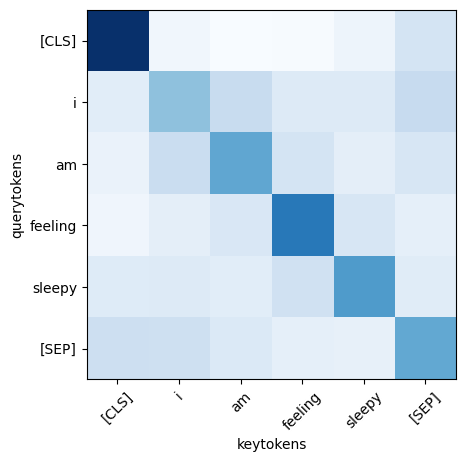

In [23]:
import matplotlib.pyplot as plt
tokens=tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

plt.imshow(attention,cmap="Blues")
plt.xticks(range(len(tokens)),tokens,rotation=45)
plt.yticks(range(len(tokens)),tokens)

plt.xlabel("keytokens")
plt.ylabel("querytokens")
plt.show()

